# Premier League 2025/26: Football Data Analysis

This notebook combines team-level attack and defence analysis with home–away comparisons and player-level exploration. It presents the data checks, calculations, charts and statistical tests in execution order.

Run the code cells from top to bottom using **Shift + Enter**. Keep `season-2526.csv` and `players_data-2025_2026.csv` beside the notebook. Outputs are included for reference; the original CSV files are not modified. Source links and collection dates still need to be documented in the proposal.

## Section 1: Setup and Data Loading

Prepare the Python environment and load the match and player datasets. Keep both original CSV files in the same folder as this notebook.

### Section 1.1 Import Libraries

Import the libraries used for tables, numerical calculations, charts and statistical tests. The commented installation command is only needed if a required package is missing.

In [1]:
# Run this only if an import fails, then restart the kernel if needed:
# %pip install pandas numpy matplotlib seaborn scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_rel, t
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 15)
print("Libraries imported successfully.")

Libraries imported successfully.


### Section 1.2 Load Datasets

Read the two CSV files into Pandas DataFrames and create working copies. The printed dimensions confirm how many records and columns were loaded.

In [2]:
players_raw = pd.read_csv("players_data-2025_2026.csv")
matches_raw = pd.read_csv("season-2526.csv")
players = players_raw.copy()
matches = matches_raw.copy()
print("Player data shape:", players.shape)
print("Match data shape:", matches.shape)

Player data shape: (2839, 102)
Match data shape: (380, 22)


## Section 2: Data Inspection and Cleaning

Inspect the structure and quality of the data before calculating statistics. Cleaning decisions are based on the checks shown below, while the original tables remain unchanged.

### Section 2.1 Preview and Inspect Data

Preview representative records and inspect column names, data types and numerical summaries. Check the league labels and date range to understand the coverage of each file.

In [3]:
display(players[["Player", "Squad", "Comp", "Pos", "MP", "Gls", "Ast"]].head())
display(matches.head())

,Player,Squad,Comp,Pos,MP,Gls,Ast
0,Brenden Aaronson,Leeds United,eng Premier League,"MF,FW",37,4,5
1,Jerome Abbey,Wolves,eng Premier League,MF,1,0,0
2,Zach Abbott,Nottingham Forest,eng Premier League,DF,3,0,0
3,Jones El-Abdellaoui,Celta Vigo,es La Liga,"MF,FW",22,2,0
4,Himad Abdelli,Marseille,fr Ligue 1,MF,8,0,0


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,...,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,...,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,...,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,...,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,...,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,...,8,6,5,0,0,0,0


In [4]:
print("Player columns:", players.columns.tolist())
players[["Player", "Squad", "Comp", "Pos", "Saves", "SoTA", "GA"]].info()
matches.info()
print("Leagues in player data:")
print(players["Comp"].value_counts())

Player columns: ['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Rk_stats_keeper', 'Nation_stats_keeper', 'Pos_stats_keeper', 'Comp_stats_keeper', 'Age_stats_keeper', 'Born_stats_keeper', 'MP_stats_keeper', 'Starts_stats_keeper', 'Min_stats_keeper', '90s_stats_keeper', 'GA', 'GA90', 'SoTA', 'Saves', 'Save%', 'W', 'D', 'L', 'CS', 'CS%', 'PKatt_stats_keeper', 'PKA', 'PKsv', 'PKm', 'Rk_stats_shooting', 'Nation_stats_shooting', 'Pos_stats_shooting', 'Comp_stats_shooting', 'Age_stats_shooting', 'Born_stats_shooting', '90s_stats_shooting', 'Gls_stats_shooting', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'PK_stats_shooting', 'PKatt_stats_shooting', 'Rk_stats_playing_time', 'Nation_stats_playing_time', 'Pos_stats_playing_time', 'Comp_stats_playing_time', 'Age_stats_playing_time', 'Born_stats_playing_time', 'MP_stats_playing_time', 'Min_stats_playing_time', 'Mn/MP'

In [5]:
display(matches.describe().round(2))
display(players[["Age", "Min", "Gls", "Ast"]].describe().round(2))
print("Raw match date range:", matches.Date.min(), "to", matches.Date.max())

Raw match date range: 2025-08-15 to 2026-05-24


,FTHG,FTAG,HTHG,HTAG,HS,AS,HST,...,AF,HC,AC,HY,AY,HR,AR
count,380.00,380.00,380.00,380.00,380.00,380.00,380.00,...,380.00,380.00,380.00,380.00,380.00,380.00,380.00
mean,1.53,1.22,0.69,0.50,13.84,11.16,4.50,...,10.99,5.39,4.60,1.67,2.08,0.05,0.05
std,1.17,1.08,0.78,0.74,4.95,4.57,2.24,...,3.40,2.73,2.75,1.23,1.32,0.24,0.22
min,0.00,0.00,0.00,0.00,1.00,3.00,0.00,...,3.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,0.00,0.00,0.00,11.00,8.00,3.00,...,9.00,3.00,3.00,1.00,1.00,0.00,0.00
50%,1.00,1.00,1.00,0.00,14.00,11.00,4.00,...,11.00,5.00,4.00,2.00,2.00,0.00,0.00
75%,2.00,2.00,1.00,1.00,16.25,14.00,6.00,...,13.00,7.00,6.00,2.00,3.00,0.00,0.00
max,5.00,5.00,3.00,4.00,35.00,30.00,11.00,...,21.00,14.00,15.00,5.00,6.00,2.00,1.00


,Age,Min,Gls,Ast
count,2837.00,2839.00,2839.00,2839.00
mean,24.86,1218.58,1.66,1.16
std,4.62,963.22,2.93,1.83
min,15.00,1.00,0.00,0.00
25%,21.00,320.50,0.00,0.00
50%,25.00,1074.00,0.00,0.00
75%,28.00,1972.50,2.00,2.00
max,41.00,3420.00,36.00,21.00


### Section 2.2 Check Data Quality

Count missing values and duplicate records, then check result codes and impossible numerical combinations. These checks identify issues that require attention before analysis.

In [6]:
missing = players.isna().sum()
print("Missing player values (columns with missing entries):")
print(missing[missing > 0].to_string())
print("Missing match values:", matches.isna().sum().sum())
print("Duplicate matches:", matches.duplicated(["Date", "HomeTeam", "AwayTeam"]).sum())
print("Duplicate player-team records:", players.duplicated(["Player", "Squad"]).sum())

Missing player values (columns with missing entries):
Nation                          3
Age                             2
Born                            2
Rk_stats_keeper              2645
Nation_stats_keeper          2645
Pos_stats_keeper             2645
Comp_stats_keeper            2645
Age_stats_keeper             2645
Born_stats_keeper            2645
MP_stats_keeper              2645
Starts_stats_keeper          2645
Min_stats_keeper             2645
90s_stats_keeper             2645
GA                           2645
GA90                         2645
SoTA                         2645
Saves                        2645
Save%                        2649
W                            2645
D                            2645
L                            2645
CS                           2645
CS%                          2651
PKatt_stats_keeper           2645
PKA                          2645
PKsv                         2645
PKm                          2645
Nation_stats_shooting       

In [7]:
match_numeric = ["FTHG", "FTAG", "HS", "AS", "HST", "AST", "HC", "AC", "HY", "AY", "HR", "AR"]
print("Match-result codes:", matches.FTR.unique())
print("Negative numeric values:", (matches[match_numeric] < 0).sum().sum())
print("Shots on target exceeding shots:", ((matches.HST > matches.HS) | (matches.AST > matches.AS)).sum())

Match-result codes: <ArrowStringArray>
['H', 'D', 'A']
Length: 3, dtype: str
Negative numeric values: 0
Shots on target exceeding shots: 0


### Section 2.3 Clean and Filter Data

Convert dates and numerical fields, select Premier League players and standardise team names. Assertions stop execution if required values or record keys fail validation.

In [8]:
# Keep raw data unchanged; stop if required match values are invalid.
matches["Date"] = pd.to_datetime(matches["Date"], errors="raise")
for col in match_numeric:
    matches[col] = pd.to_numeric(matches[col], errors="raise")
assert matches[match_numeric + ["HomeTeam", "AwayTeam", "FTR", "Date"]].notna().all().all()
assert (matches[match_numeric] >= 0).all().all()
assert (matches.HST <= matches.HS).all() and (matches.AST <= matches.AS).all()
for col in ["Age", "Min", "Gls", "Ast", "Saves", "SoTA", "GA"]:
    players[col] = pd.to_numeric(players[col], errors="raise")
print("Parsed match dates:", matches.Date.min().date(), "to", matches.Date.max().date())

Parsed match dates: 2025-08-15 to 2026-05-24


In [9]:
name_map = {'Manchester City':'Man City','Manchester Utd':'Man United','Newcastle United':'Newcastle','Nottingham Forest':"Nott'm Forest",'Tottenham Hotspur':'Tottenham','West Ham United':'West Ham','Leeds United':'Leeds'}
epl = players.loc[players.Comp.eq('eng Premier League')].copy()
epl['Team'] = epl.Squad.replace(name_map)
teams = set(matches.HomeTeam) | set(matches.AwayTeam)
assert set(epl.Team) == teams, 'Team coverage mismatch'
assert not matches.duplicated(['Date','HomeTeam','AwayTeam']).any()
assert not epl.duplicated(['Player','Squad']).any()
assert matches[['FTHG','FTAG','HS','AS','HST','AST']].notna().all().all()
print('Matched teams:', len(teams), '| EPL player records:', len(epl))
print('Duplicate match and player-team keys: none')

Matched teams: 20 | EPL player records: 551
Duplicate match and player-team keys: none


In [10]:
keepers = epl.loc[epl.Pos.str.contains("GK", na=False)].copy()
assert keepers[["Saves", "SoTA", "GA"]].notna().all().all()
assert (keepers[["Saves", "SoTA", "GA"]] >= 0).all().all()
assert (keepers.Saves <= keepers.SoTA).all()
expected_results = np.select([matches.FTHG > matches.FTAG, matches.FTHG == matches.FTAG], ["H", "D"], default="A")
assert (matches.FTR == expected_results).all()
print("Goalkeeper records:", len(keepers))
print("Goalkeeper values and match-result codes passed the checks.")

Goalkeeper records: 40
Goalkeeper values and match-result codes passed the checks.


Goalkeeper fields are not applicable to outfield players and are not filled with zero or an overall average. Missing age is handled only in Section 6.1; no unnecessary rows are dropped.

## Section 3: Team Statistics and Data Integration

Convert individual match and player records into team-level statistics. Align team names and check overlapping measurements before combining the sources.

### Section 3.1 Calculate Team Statistics

Represent each match from both teams’ perspectives and aggregate the records by team. Calculate points, per-match rates, shot accuracy and an aggregate goal-conversion measure.

In [11]:
home = matches[['HomeTeam','FTHG','FTAG','HS','HST','AST']].copy()
away = matches[['AwayTeam','FTAG','FTHG','AS','AST','HST']].copy()
cols = ['Team','GF','GA','Shots','ShotsOnTarget','ShotsOnTargetAgainst']
home.columns = away.columns = cols
long = pd.concat([home,away], ignore_index=True)
long['Points'] = np.select([long.GF > long.GA,long.GF == long.GA],[3,1],default=0)

print("Team-match rows:", len(long))
display(long.head())

Team-match rows: 760


,Team,GF,GA,Shots,ShotsOnTarget,ShotsOnTargetAgainst,Points
0,Liverpool,4,2,19,10,3,3
1,Aston Villa,0,0,3,3,3,1
2,Brighton,1,1,10,4,2,1
3,Sunderland,3,0,10,5,4,3
4,Tottenham,3,0,16,6,4,3


In [12]:
summary = long.groupby('Team')[cols[1:]+['Points']].sum()
summary['Played'] = long.groupby('Team').size()
assert summary.Played.eq(38).all()
for raw,new in [('GF','GoalsPerMatch'),('GA','ConcededPerMatch'),('Shots','ShotsPerMatch'),('ShotsOnTargetAgainst','OppSOTPerMatch')]:
    summary[new] = summary[raw] / summary.Played
summary['ShotAccuracy'] = summary.ShotsOnTarget / summary.Shots

display(summary[["Played", "Points", "GF", "GA", "GoalsPerMatch", "ConcededPerMatch"]].round(3))
summary["GoalConversion"] = summary.GF / summary.Shots
# Goal conversion includes all team goals, including penalties and own goals.
# It is an aggregate proxy, not a shot-by-shot finishing probability.
assert summary.GF.sum() == summary.GA.sum()
assert summary.Points.sum() == 3 * matches.FTR.ne("D").sum() + 2 * matches.FTR.eq("D").sum()
display(summary[["Points", "ShotsPerMatch", "ShotAccuracy", "GoalConversion"]].round(3))

,Played,Points,GF,GA,GoalsPerMatch,ConcededPerMatch
Team,,,,,,
Arsenal,38,85,71,27,1.868,0.711
Aston Villa,38,65,56,49,1.474,1.289
Bournemouth,38,57,58,54,1.526,1.421
Brentford,38,53,55,52,1.447,1.368
Brighton,38,53,52,46,1.368,1.211
Burnley,38,22,38,75,1.000,1.974
Chelsea,38,52,58,52,1.526,1.368
Crystal Palace,38,45,41,51,1.079,1.342
Everton,38,49,47,50,1.237,1.316


,Points,ShotsPerMatch,ShotAccuracy,GoalConversion
Team,,,,
Arsenal,85,14.526,0.337,0.129
Aston Villa,65,12.711,0.352,0.116
Bournemouth,57,13.816,0.339,0.110
Brentford,53,10.658,0.363,0.136
Brighton,53,13.026,0.356,0.105
Burnley,22,9.342,0.332,0.107
Chelsea,52,13.447,0.321,0.114
Crystal Palace,45,11.632,0.319,0.093
Everton,49,11.053,0.343,0.112


### Section 3.2 Aggregate and Merge Player Data

Aggregate goalkeeper records and join them to the match-based team table. Difference columns reveal where the two sources report inconsistent totals.

In [13]:
keeper_totals = keepers.groupby("Team")[["Saves", "SoTA", "GA"]].sum(min_count=1)
keeper_totals = keeper_totals.rename(columns={"SoTA":"KeeperSoTA", "GA":"KeeperGA"})
summary = summary.join(keeper_totals, how="left", validate="one_to_one")
assert summary[["Saves", "KeeperSoTA", "KeeperGA"]].notna().all().all()
assert summary.KeeperSoTA.gt(0).all()
summary["SaveRate"] = summary.Saves / summary.KeeperSoTA
summary["SOTSourceDifference"] = summary.KeeperSoTA - summary.ShotsOnTargetAgainst
summary["GASourceDifference"] = summary.KeeperGA - summary.GA
summary = summary.sort_values("Points", ascending=False)
display(summary[["Points", "SaveRate", "SOTSourceDifference", "GASourceDifference"]].round(3))

,Points,SaveRate,SOTSourceDifference,GASourceDifference
Team,,,,
Arsenal,85,0.685,-1.0,0.0
Man City,78,0.718,-3.0,0.0
Man United,71,0.659,-3.0,0.0
Aston Villa,65,0.708,-7.0,0.0
Liverpool,60,0.669,-5.0,0.0
Bournemouth,57,0.694,-5.0,0.0
Sunderland,54,0.724,-4.0,0.0
Brentford,53,0.707,-12.0,0.0
Brighton,53,0.710,-3.0,0.0


The two sources disagree on shots-on-target totals for all teams, and on goalkeeper goals conceded for Chelsea. Definitions or coverage must be checked using source documentation. Keep goalkeeper metrics out of headline conclusions until reconciled.

## Section 4: Attack, Defence and League Points

Examine how attacking and defensive indicators relate to league points. Use correlations and scatter plots to describe the patterns observed in this season.

### Section 4.1 Analyse Relationships and Visualise Results

Calculate Pearson and Spearman correlations with points, then compare goals scored and conceded in two scatter plots. The fitted lines describe this season’s relationships rather than predicting future results.

In [14]:
metrics = ["GoalsPerMatch", "ConcededPerMatch", "ShotsPerMatch", "ShotAccuracy", "GoalConversion", "OppSOTPerMatch"]
correlations = pd.DataFrame({
    "Pearson r with points": summary[metrics].corrwith(summary.Points),
    "Spearman rho with points": summary[metrics].rank().corrwith(summary.Points.rank())
})
display(correlations.round(3))

,Pearson r with points,Spearman rho with points
GoalsPerMatch,0.908,0.829
ConcededPerMatch,-0.900,-0.754
ShotsPerMatch,0.810,0.766
ShotAccuracy,0.131,0.191
GoalConversion,0.674,0.583
OppSOTPerMatch,-0.837,-0.635


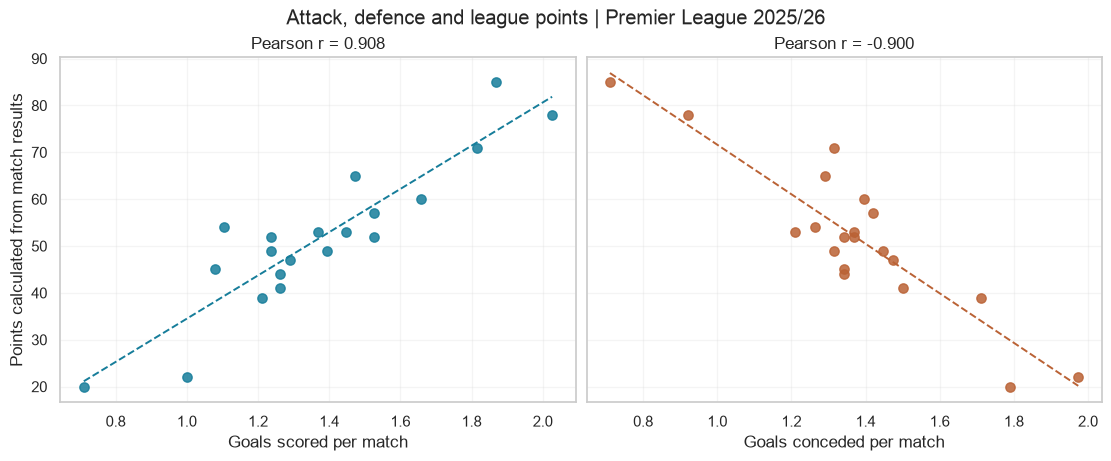

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, layout="constrained")
for ax, metric, label, colour in zip(
    axes, ["GoalsPerMatch", "ConcededPerMatch"],
    ["Goals scored per match", "Goals conceded per match"], ["#167d9a", "#ba6235"]):
    x = summary[metric]
    y = summary["Points"]
    ax.scatter(x, y, color=colour, s=45, alpha=0.85)
    slope, intercept = np.polyfit(x, y, 1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.plot(grid, slope * grid + intercept, "--", color=colour, linewidth=1.4)
    ax.set_xlabel(label)
    ax.set_title(f"Pearson r = {x.corr(y):.3f}")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Points calculated from match results")
fig.suptitle("Attack, defence and league points | Premier League 2025/26")
plt.show()

These are same-season associations. Goals also determine match points; correlations do not establish that attack or defence is causally more important.

## Section 5: Home and Away Comparisons

Compare home and away outcomes, attacking activity and disciplinary records. Follow the descriptive comparisons with exploratory paired tests of attacking statistics.

### Section 5.1 Compare Match Outcomes

Count home wins, draws and away wins, and express each as a percentage of all matches. This table provides context for the performance comparisons that follow.

In [16]:
result_counts = matches.FTR.value_counts().reindex(["H", "D", "A"], fill_value=0)
outcome_table = pd.DataFrame({"Matches": result_counts, "Percentage": result_counts / len(matches) * 100})
outcome_table.index = ["Home win", "Draw", "Away win"]
display(outcome_table.round(2))

,Matches,Percentage
Home win,162,42.63
Draw,104,27.37
Away win,114,30.00


### Section 5.2 Compare Attacking Statistics

Compare average shots, shots on target and corners for the home and away sides. The table gives precise values, while the grouped bar chart makes the differences easier to compare.

,Home,Away
Shots,13.839,11.158
Shots on target,4.503,3.871
Corners,5.395,4.603


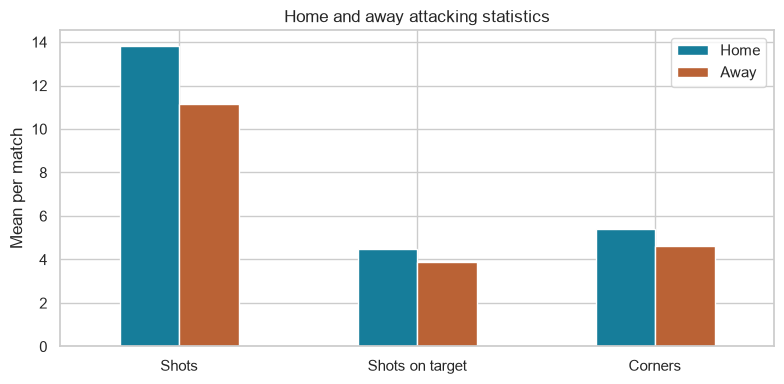

In [17]:
attack_pairs = {"Shots": ("HS", "AS"), "Shots on target": ("HST", "AST"), "Corners": ("HC", "AC")}
attack_stats = pd.DataFrame({label: {"Home": matches[h].mean(), "Away": matches[a].mean()}
                             for label, (h, a) in attack_pairs.items()}).T
display(attack_stats.round(3))
ax = attack_stats.plot.bar(figsize=(8, 4), color=["#167d9a", "#ba6235"], rot=0)
ax.set(title="Home and away attacking statistics", ylabel="Mean per match", xlabel="")
plt.tight_layout()
plt.show()

### Section 5.3 Inspect Paired Differences

Calculate home-minus-away differences within each match. Inspect their spread and extreme values before interpreting the paired t-tests.

,count,mean,std,min,25%,50%,75%,max
Shots,380.0,2.682,7.818,-24.0,-2.0,3.0,8.0,28.0
Shots on target,380.0,0.632,3.294,-9.0,-2.0,1.0,3.0,10.0
Corners,380.0,0.792,4.397,-14.0,-2.0,1.0,4.0,12.0


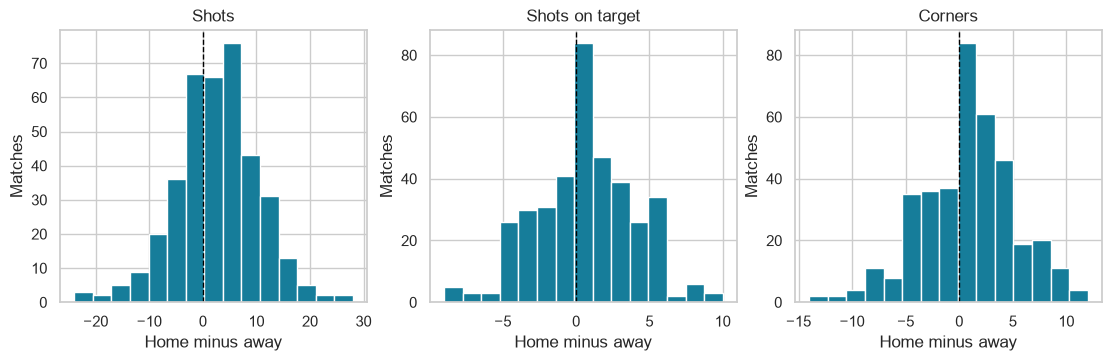

In [18]:
# One difference per match: home minus away.
differences = pd.DataFrame({label: matches[h] - matches[a] for label, (h, a) in attack_pairs.items()})
display(differences.describe().T.round(3))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), layout="constrained")
for ax, label in zip(axes, differences.columns):
    ax.hist(differences[label], bins=15, color="#167d9a", edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(title=label, xlabel="Home minus away", ylabel="Matches")
plt.show()

### Section 5.4 Perform Paired t-tests

Test whether the average within-match difference is zero for each attacking metric. Report effect sizes and confidence intervals alongside p-values, and use Holm adjustment for the three comparisons.

Two-sided tests: H₀ = the mean within-match difference is zero. H₁ = it is not zero. The pairing is within each match. Repeated teams across matches still create dependence, so p-values and confidence intervals are exploratory and rely on an independence approximation between match differences. The 95% intervals are pointwise, not simultaneous.

In [19]:
test_rows = []
for label, (h, a) in attack_pairs.items():
    d = differences[label]
    n = len(d)
    mean_diff = d.mean()
    sd_diff = d.std(ddof=1)
    se = sd_diff / np.sqrt(n)
    margin = t.ppf(0.975, df=n - 1) * se
    result = ttest_rel(matches[h], matches[a], alternative="two-sided")
    test_rows.append({"Metric": label, "N pairs": n, "Home mean": matches[h].mean(),
        "Away mean": matches[a].mean(), "Mean H-A": mean_diff,
        "CI95 lower": mean_diff - margin, "CI95 upper": mean_diff + margin,
        "t statistic": result.statistic, "df": n - 1, "Raw p": result.pvalue,
        "Cohen dz": mean_diff / sd_diff})
tests = pd.DataFrame(test_rows).set_index("Metric")

# Holm adjustment controls multiple testing across the three attacking tests,
# assuming the underlying p-values are valid.
pvalues = tests["Raw p"].to_numpy()
order = np.argsort(pvalues)
adjusted = np.empty(len(pvalues))
adjusted[order] = np.minimum(1, np.maximum.accumulate(pvalues[order] * (len(pvalues) - np.arange(len(pvalues)))))
tests["Holm p"] = adjusted
tests["Holm p < 0.05"] = tests["Holm p"] < 0.05
assert np.isfinite(tests.select_dtypes(include="number")).all().all()
assert ((tests["Holm p"] >= tests["Raw p"] - 1e-15) & (tests["Holm p"] <= 1)).all()
display(tests.style.format({"Home mean":"{:.3f}", "Away mean":"{:.3f}", "Mean H-A":"{:.3f}",
    "CI95 lower":"{:.3f}", "CI95 upper":"{:.3f}", "t statistic":"{:.3f}",
    "Raw p":"{:.3g}", "Holm p":"{:.3g}", "Cohen dz":"{:.3f}"}))

,N pairs,Home mean,Away mean,Mean H-A,CI95 lower,CI95 upper,t statistic,df,Raw p,Cohen dz,Holm p,Holm p < 0.05
Metric,,,,,,,,,,,,
Shots,380,13.839,11.158,2.682,1.893,3.470,6.687,379,8.2e-11,0.343,2.46e-10,True
Shots on target,380,4.503,3.871,0.632,0.299,0.964,3.738,379,0.000214,0.192,0.000429,True
Corners,380,5.395,4.603,0.792,0.349,1.236,3.511,379,0.000499,0.180,0.000499,True


The draft’s independent-sample tests and duplicated home/away win contingency table are not used. A small p-value does not measure practical importance or prove a causal home effect; inspect the difference, interval and effect size too.

### Section 5.5 Compare Disciplinary Statistics

Summarise yellow and red cards using averages, medians, maxima and the percentage of zero-card observations. Keep this comparison descriptive because the counts, particularly red cards, are sparse.

In [20]:
card_rows = []
for label, h, a in [("Yellow cards", "HY", "AY"), ("Red cards", "HR", "AR")]:
    card_rows.append({"Card": label, "Home mean": matches[h].mean(), "Away mean": matches[a].mean(),
        "Home median": matches[h].median(), "Away median": matches[a].median(),
        "Home maximum": matches[h].max(), "Away maximum": matches[a].max(),
        "Home zero %": matches[h].eq(0).mean()*100, "Away zero %": matches[a].eq(0).mean()*100,
        "Mean H-A": (matches[h]-matches[a]).mean()})
display(pd.DataFrame(card_rows).set_index("Card").round(3))

,Home mean,Away mean,Home median,Away median,Home maximum,Away maximum,Home zero %,Away zero %,Mean H-A
Card,,,,,,,,,
Yellow cards,1.666,2.082,2.0,2.0,5,6,18.684,11.316,-0.416
Red cards,0.050,0.053,0.0,0.0,2,1,95.526,94.737,-0.003


Red cards are sparse counts. This section is descriptive; no ordinary t-test or referee-bias conclusion is applied.

## Section 6: Player-Level Exploration

Explore the relationship between player age and scoring. Consider position and playing time when comparing players with different roles and levels of participation.

### Section 6.1 Explore Age and Scoring

First examine age and total goals, then calculate goals per 90 minutes and group players by position. Apply a minimum-playing-time threshold and check alternative thresholds to assess how filtering affects the observed associations.

In [21]:
# Keep the original age-versus-total-goals exploration, then account for exposure.
valid_player = epl[["Age", "Min", "Gls"]].notna().all(axis=1) & epl.Min.gt(0) & epl.Pos.notna()
assert (epl.loc[valid_player, ["Min", "Gls"]] >= 0).all().all()
scoring = epl.loc[valid_player].copy()
scoring["PrimaryPosition"] = scoring.Pos.str.split(",").str[0]
scoring = scoring.loc[scoring.PrimaryPosition.ne("GK")].copy()
scoring["GoalsPer90"] = scoring.Gls * 90 / scoring.Min
minimum_minutes = 900  # Ten full matches; a transparent small-exposure filter.
regulars = scoring.loc[scoring.Min >= minimum_minutes].copy()
print("EPL player records:", len(epl))
print("Excluded for missing age/minutes/goals/position or zero minutes:", (~valid_player).sum())
print("Eligible outfield records:", len(scoring))
print("Outfield records with at least 900 minutes:", len(regulars))
display(regulars.groupby("PrimaryPosition")[["Age", "Min", "Gls", "GoalsPer90"]].agg(["count", "mean", "median"]).round(3))

EPL player records: 551
Excluded for missing age/minutes/goals/position or zero minutes: 0
Eligible outfield records: 511
Outfield records with at least 900 minutes: 315


Age                  Min                     Gls         \
                count    mean median count      mean  median count   mean   
PrimaryPosition                                                             
DF                122  25.811   25.0   122  2082.311  1933.0   122  1.016   
FW                 44  26.068   25.0    44  1750.205  1653.5    44  7.273   
MF                149  24.758   25.0   149  1962.315  1841.0   149  3.262   

                       GoalsPer90                
                median      count   mean median  
PrimaryPosition                                  
DF                 1.0        122  0.041  0.030  
FW                 6.0         44  0.340  0.324  
MF                 2.0        149  0.145  0.116

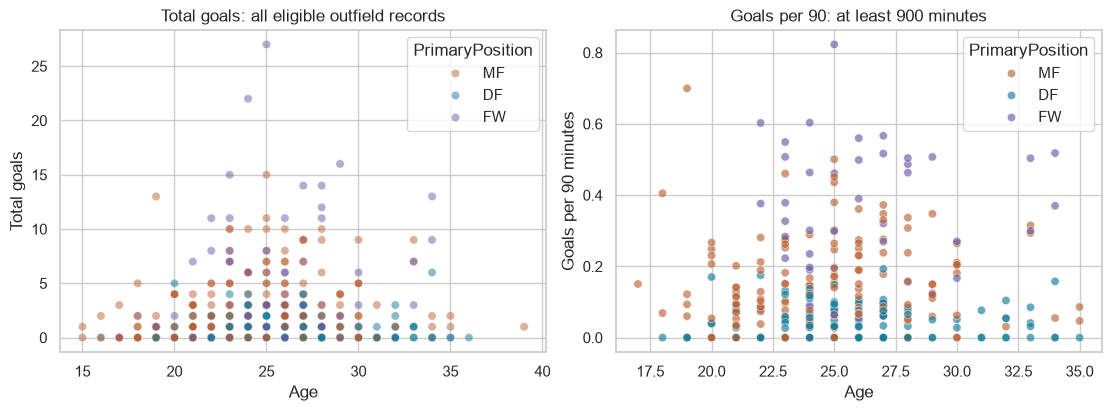

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
palette = {"DF":"#167d9a", "MF":"#ba6235", "FW":"#6e59a5"}
sns.scatterplot(data=scoring, x="Age", y="Gls", hue="PrimaryPosition", palette=palette, alpha=0.5, ax=axes[0])
axes[0].set(title="Total goals: all eligible outfield records", xlabel="Age", ylabel="Total goals")
sns.scatterplot(data=regulars, x="Age", y="GoalsPer90", hue="PrimaryPosition", palette=palette, alpha=0.65, ax=axes[1])
axes[1].set(title="Goals per 90: at least 900 minutes", xlabel="Age", ylabel="Goals per 90 minutes")
plt.show()

In [23]:
# Descriptive sensitivity check for the playing-time threshold.
threshold_rows = []
for cutoff in [450, 900, 1350]:
    subset = scoring.loc[scoring.Min >= cutoff]
    for position, group in subset.groupby("PrimaryPosition"):
        threshold_rows.append({"Minimum minutes": cutoff, "Position": position, "Records": len(group),
            "Age vs goals/90 (Pearson r)": group.Age.corr(group.GoalsPer90)})
display(pd.DataFrame(threshold_rows).round(3))

,Minimum minutes,Position,Records,Age vs goals/90 (Pearson r)
0,450,DF,139,-0.038
1,450,FW,56,0.106
2,450,MF,182,0.034
3,900,DF,122,-0.008
4,900,FW,44,0.119
5,900,MF,149,0.030
6,1350,DF,96,-0.035
7,1350,FW,31,-0.021
8,1350,MF,115,-0.007


This is supplementary exploration, not evidence that age causes scoring differences. Per-90 rates and position groups reduce some comparability problems but do not account for team quality, role or selection. A transferred player may contribute more than one team record. Source URLs and collection dates must be documented in the proposal.